# Identifikasi Dataset 3: Klasifikasi Multilabel
**Dataset:** Indonesian Multi-label Hate Speech and Abusive Language (Twitter)

## Keterangan dataset
- **Sumber:** GitHub `okkyibrohim/id-multi-label-hate-speech-and-abusive-language-detection`, file `re_dataset.csv`. Ibrohim & Budi (2019), *Multi-label Hate Speech and Abusive Language Detection in Indonesian Twitter*, ALW3, ACL. Sekitar 13.169 tweet.
- **Jenis data:** **teks** (tweet berbahasa Indonesia).
- **Label (biner 0/1):** `HS`, `Abusive`, `HS_Individual`, `HS_Group`, `HS_Religion`, `HS_Race`, `HS_Physical`, `HS_Gender`, `HS_Other`, `HS_Weak`, `HS_Moderate`, `HS_Strong`.
- **Tujuan:** satu tweet dapat memiliki beberapa label sekaligus, misalnya hate speech, abusive, ditujukan ke individu, dan tingkat kerasnya.

In [1]:
import os, urllib.request
import pandas as pd

URL  = "https://raw.githubusercontent.com/okkyibrohim/id-multi-label-hate-speech-and-abusive-language-detection/master/re_dataset.csv"
FILE = "re_dataset.csv"

if not os.path.exists(FILE):
    urllib.request.urlretrieve(URL, FILE)

def read_csv_safe(path):
    """Baca CSV dengan mencoba beberapa encoding."""
    for enc in ("utf-8", "latin-1"):
        try:
            return pd.read_csv(path, encoding=enc)
        except UnicodeDecodeError:
            continue
    raise ValueError("Encoding file tidak dikenali")

df = read_csv_safe(FILE)
print("Kolom:", list(df.columns))
df.head()

Kolom: ['Tweet', 'HS', 'Abusive', 'HS_Individual', 'HS_Group', 'HS_Religion', 'HS_Race', 'HS_Physical', 'HS_Gender', 'HS_Other', 'HS_Weak', 'HS_Moderate', 'HS_Strong']


,Tweet,HS,Abusive,HS_Individual,HS_Group,HS_Religion,HS_Race,HS_Physical,HS_Gender,HS_Other,HS_Weak,HS_Moderate,HS_Strong
0,- disaat semua cowok berusaha melacak perhatia...,1,1,1,0,0,0,0,0,1,1,0,0
1,RT USER: USER siapa yang telat ngasih tau elu?...,0,1,0,0,0,0,0,0,0,0,0,0
2,"41. Kadang aku berfikir, kenapa aku tetap perc...",0,0,0,0,0,0,0,0,0,0,0,0
3,USER USER AKU ITU AKU\n\nKU TAU MATAMU SIPIT T...,0,0,0,0,0,0,0,0,0,0,0,0
4,USER USER Kaum cebong kapir udah keliatan dong...,1,1,0,1,1,0,0,0,0,0,1,0


## Pisahkan fitur (X) dan label (y)

In [2]:
text_col   = df.select_dtypes("object").apply(lambda s: s.astype(str).str.len().mean()).idxmax()
label_cols = [c for c in df.columns if c != text_col]

X = df[text_col]       # data fitur (teks tweet)
y = df[label_cols]     # data label (kolom biner 0/1)

print("Kolom fitur     :", text_col)
print("Kolom label     :", label_cols)
print("Jumlah data     :", df.shape[0])
print("Jumlah variabel :", df.shape[1], f"(1 fitur teks + {len(label_cols)} label)")

Kolom fitur     : Tweet
Kolom label     : ['HS', 'Abusive', 'HS_Individual', 'HS_Group', 'HS_Religion', 'HS_Race', 'HS_Physical', 'HS_Gender', 'HS_Other', 'HS_Weak', 'HS_Moderate', 'HS_Strong']
Jumlah data     : 13169
Jumlah variabel : 13 (1 fitur teks + 12 label)


C:\Users\Fauzan\AppData\Local\Temp\ipykernel_15644\3045873883.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_col   = df.select_dtypes("object").apply(lambda s: s.astype(str).str.len().mean()).idxmax()


In [3]:
df.info()
print(df.isna().sum().sum(), "missing value")

<class 'pandas.DataFrame'>
RangeIndex: 13169 entries, 0 to 13168
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   Tweet          13169 non-null  str  
 1   HS             13169 non-null  int64
 2   Abusive        13169 non-null  int64
 3   HS_Individual  13169 non-null  int64
 4   HS_Group       13169 non-null  int64
 5   HS_Religion    13169 non-null  int64
 6   HS_Race        13169 non-null  int64
 7   HS_Physical    13169 non-null  int64
 8   HS_Gender      13169 non-null  int64
 9   HS_Other       13169 non-null  int64
 10  HS_Weak        13169 non-null  int64
 11  HS_Moderate    13169 non-null  int64
 12  HS_Strong      13169 non-null  int64
dtypes: int64(12), str(1)
memory usage: 1.3 MB
0 missing value


Jumlah tweet per label:
HS               5561
Abusive          5043
HS_Other         3740
HS_Individual    3575
HS_Weak          3383
HS_Group         1986
HS_Moderate      1705
HS_Religion       793
HS_Race           566
HS_Strong         473
HS_Physical       323
HS_Gender         306
dtype: int64


<Axes: title={'center': 'Jumlah tweet per label'}>

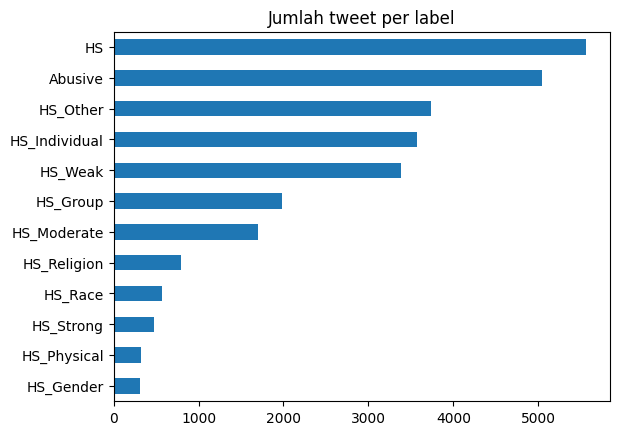

In [4]:
print("Jumlah tweet per label:")
print(y.sum().sort_values(ascending=False))
y.sum().sort_values().plot(kind="barh", title="Jumlah tweet per label")

In [5]:
n_aktif = y.sum(axis=1)
print(n_aktif.value_counts().sort_index())
print("Rata-rata label aktif per tweet:", round(n_aktif.mean(), 2))

0    5860
1    1748
4    2208
5    3251
6      95
7       7
Name: count, dtype: int64
Rata-rata label aktif per tweet: 2.08


## Kesimpulan jenis klasifikasi

In [6]:
if len(label_cols) > 1 and n_aktif.max() > 1:
    jenis = "Klasifikasi Multilabel"
elif y.shape[1] == 1 and y.iloc[:, 0].nunique() == 2:
    jenis = "Klasifikasi Biner"
else:
    jenis = "Klasifikasi Multikelas"
print(f"Ada {len(label_cols)} kolom label, maksimal {n_aktif.max()} label aktif pada satu tweet")
print("Kesimpulan:", jenis)

Ada 12 kolom label, maksimal 7 label aktif pada satu tweet
Kesimpulan: Klasifikasi Multilabel


**Kesimpulan:** Dataset ini **Klasifikasi Multilabel** pada **data teks**. Ada **12 kolom label** biner (0/1) dan satu tweet dapat memiliki **lebih dari satu label aktif sekaligus**, sehingga labelnya tidak saling eksklusif seperti pada multikelas.